# Appendix — PyTorch versions of the Chapter 8 VAE and Chapter 9 CNN

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mengrenman/artificial_intelligence_engines/blob/main/notebooks/appendix_pytorch.ipynb)

The other notebooks use only NumPy, with every backward pass derived and coded by hand. This optional appendix
re-implements two of the larger models with PyTorch (`scripts/torch_models.py`), where gradients come from
automatic differentiation:

- `TorchVAE`: the variational autoencoder of Chapter 8 (`scripts/vae.py`), with the same encoder output
  $[\mu,\log\sigma^2]$, reparametrisation $z=\mu+\eta\sigma$ (Section 8.6) and objective $L=L^{\rm dec}+L^{\rm enc}$
  (Eqs 8.35–8.37, with decoder variance $\sigma_x^2$).
- `TorchLeNet`: the scaled-down LeNet of Chapter 9 (`scripts/deep_backprop.lenet`, Sections 9.2–9.4), with 3×3 kernels.

First we check that, given the *same* weights, both implementations compute the same outputs and gradients. That
validates the hand-derived NumPy backprop against autograd. Then we train the torch models.
Requires the optional dependency `torch` (`pip install -e ".[torch]"`).

In [1]:
# Colab setup: install the companion package (does nothing when run locally).
try:
    import google.colab  # noqa: F401
    %pip install -q git+https://github.com/mengrenman/artificial_intelligence_engines
except ImportError:
    pass

In [2]:
import sys, pathlib; sys.path.insert(0, str(pathlib.Path.cwd().parent))
%matplotlib inline
import time
import numpy as np
import matplotlib.pyplot as plt
import torch

from aie.data import digits
from aie.losses import softmax_cross_entropy
from scripts.deep_backprop import accuracy, as_images, lenet, train_classifier
from scripts.torch_models import TorchLeNet, TorchVAE, paired_layers, torch_grads_as_numpy
from scripts.vae import VAE
torch.manual_seed(0)
t_start = time.time()

## 1. Cross-checking NumPy against autograd

`TorchVAE.from_numpy` and `TorchLeNet.from_numpy` build a float64 torch model with the same architecture and copy the
NumPy weights into it (a `Dense` weight $W$ of shape (n_in, n_out) becomes `nn.Linear.weight` $=W^\top$; conv kernels copy
unchanged). We evaluate one batch with the same noise $\eta$, run the NumPy `backward` and torch's `loss.backward()`,
and report the largest absolute difference in the loss and in each layer's $\partial E/\partial W$ and $\partial E/\partial b$.

In [3]:
def max_grad_diff(module, np_model):
    return max(np.abs(tg[k] - lay.grads[k]).max()
               for (_, lay), tg in zip(paired_layers(module, np_model), torch_grads_as_numpy(module))
               for k in ('W', 'b'))

rng = np.random.default_rng(0)
X_img, y = digits(n_per_class=100, max_shift=0, seed=0)
X = X_img.reshape(len(X_img), -1)

# Chapter 8 VAE: E = -L for a batch, with fixed noise eta of shape (N_z, T, J)
vae = VAE(144, n_latent=2, hidden=(128, 64), activation='tanh', seed=0, sigma_x2=0.1)
tvae = TorchVAE.from_numpy(vae)
xb, eta = X[:32], rng.standard_normal((1, 32, 2))
vae.backward(vae.forward(xb, eta))
E_t = tvae.loss(xb, eta); E_t.backward()
print(f'VAE   : E numpy {vae.loss(xb, eta):.10f}  torch {E_t.item():.10f}'
      f'  | max |grad diff| = {max(max_grad_diff(tvae.encoder, vae.encoder), max_grad_diff(tvae.decoder, vae.decoder)):.1e}')

# Chapter 9 LeNet: softmax cross-entropy of the logits
cnn = lenet(np.random.default_rng(0))
tcnn = TorchLeNet.from_numpy(cnn)
xi, yi = as_images(X_img[:32]), y[:32]
logits = cnn.forward(xi)
E_np, g = softmax_cross_entropy(logits, yi); cnn.backward(g)
t_logits = tcnn(torch.as_tensor(xi))
E_t = torch.nn.functional.cross_entropy(t_logits, torch.as_tensor(yi)); E_t.backward()
print(f'LeNet : E numpy {E_np:.10f}  torch {E_t.item():.10f}'
      f'  | max |logit diff| = {np.abs(t_logits.detach().numpy() - logits).max():.1e}'
      f'  | max |grad diff| = {max_grad_diff(tcnn.net, cnn):.1e}')

VAE   : E numpy 160.9533262063  torch 160.9533262063  | max |grad diff| = 8.9e-16
LeNet : E numpy 2.3279025182  torch 2.3279025182  | max |logit diff| = 0.0e+00  | max |grad diff| = 8.3e-17


The differences are at the level of float64 round-off: the hand-written backward passes in `aie.layers` and
`scripts/vae.py` compute exactly the gradients autograd does.

## 2. Training the VAE in PyTorch (Chapter 8)

Same set-up as notebook 08: centred digits (`max_shift=0`), a 2-D latent space, encoder 144-128-64-(2+2), decoder
2-64-128-144 with tanh hidden units, and $\sigma_x^2=0.1$. `fit` minimises $E=-L$ with Adam (float32).

trained in 8.2s;  final -L = 5.934  (recon 2.606, KL 3.328)


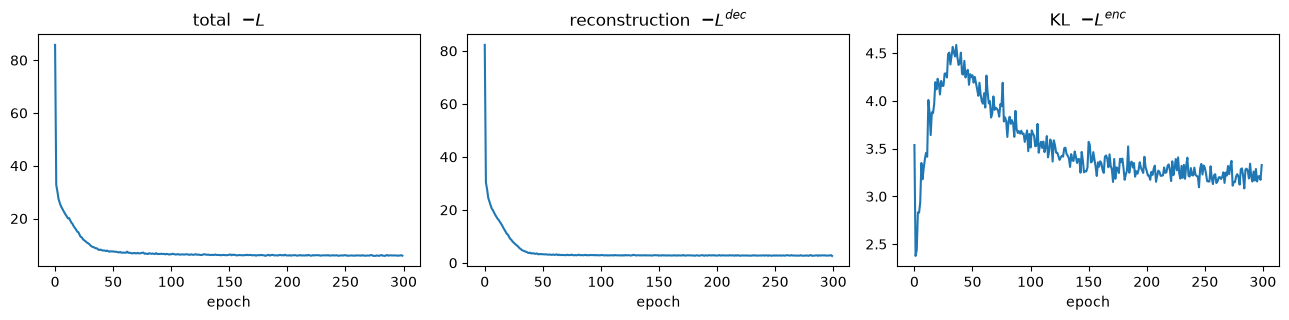

In [4]:
tv = TorchVAE(144, n_latent=2, hidden=(128, 64), activation='tanh', seed=0, sigma_x2=0.1)
t0 = time.time()
hist = tv.fit(X, n_epochs=300, lr=1e-3, batch_size=32, seed=0)
print(f'trained in {time.time() - t0:.1f}s;  final -L = {hist["loss"][-1]:.3f}'
      f'  (recon {hist["recon"][-1]:.3f}, KL {hist["kl"][-1]:.3f})')

fig, axes = plt.subplots(1, 3, figsize=(13, 3.3))
for ax, k, t in zip(axes, ['loss', 'recon', 'kl'], ['total  $-L$', 'reconstruction  $-L^{dec}$', 'KL  $-L^{enc}$']):
    ax.plot(hist[k]); ax.set_title(t); ax.set_xlabel('epoch')
fig.tight_layout()

**Latent space.** Left: encoder means $\mu$ coloured by digit label. Right: the decoder output over a grid of $z$
values at the quantiles of the $\mathcal N(0,I)$ prior (cf. notebook 08).

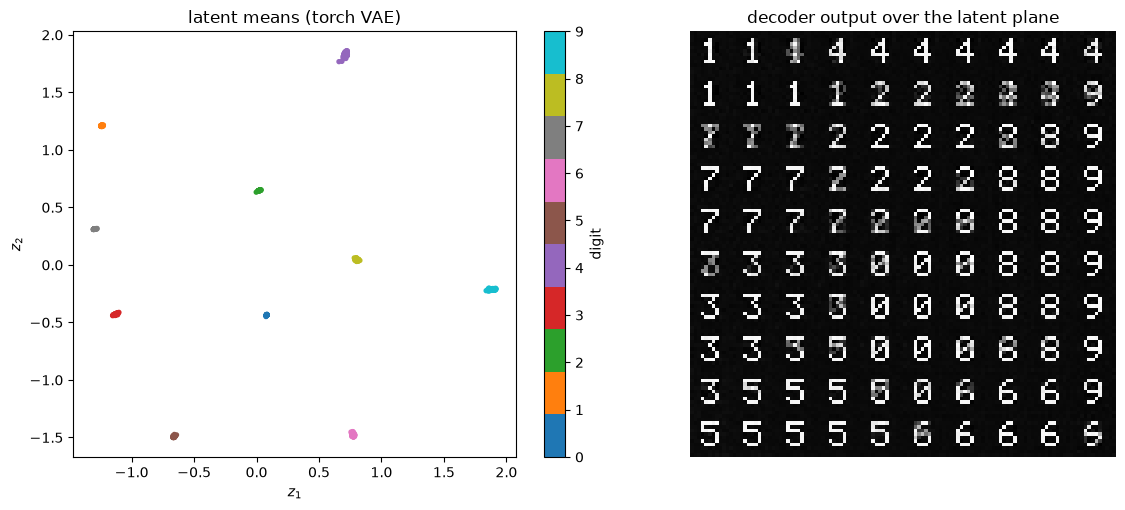

In [5]:
from scipy.stats import norm
mu, logvar = tv.encode_numpy(X)
n = 10
grid = norm.ppf(np.linspace(0.05, 0.95, n))
Z = np.array([[z1, z2] for z2 in grid[::-1] for z1 in grid])
canvas = tv.decode_numpy(Z).reshape(n, n, 12, 12).transpose(0, 2, 1, 3).reshape(n * 12, n * 12)

fig, ax = plt.subplots(1, 2, figsize=(12, 5.2))
sc = ax[0].scatter(mu[:, 0], mu[:, 1], c=y, cmap='tab10', s=8)
fig.colorbar(sc, ax=ax[0], ticks=range(10), label='digit')
ax[0].set_xlabel('$z_1$'); ax[0].set_ylabel('$z_2$'); ax[0].set_title('latent means (torch VAE)')
ax[1].imshow(canvas, cmap='gray', vmin=0, vmax=1); ax[1].axis('off'); ax[1].set_title('decoder output over the latent plane')
fig.tight_layout()

## 3. Training the LeNet in PyTorch (Chapter 9)

Same set-up as notebook 09: train on mildly shifted digits (`max_shift=1`) and test on larger shifts (`max_shift=2`).
For comparison we train the NumPy `lenet()` with the same optimiser settings. The two start from different random
weights and see mini-batches in a different order, so their curves are similar but not identical.

torch: 2.1s, train acc 1.000, shifted-test acc 0.644
numpy: 1.4s, train acc 1.000, shifted-test acc 0.602
notebook run time 12.5s


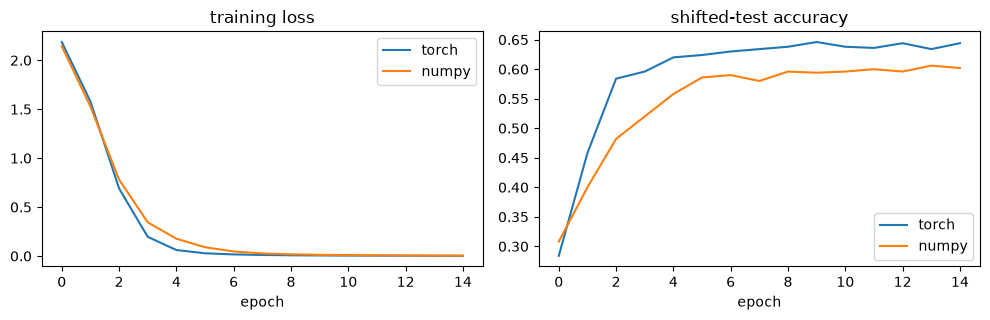

In [6]:
X_train, y_train = digits(n_per_class=100, max_shift=1, seed=0)
X_test, y_test = digits(n_per_class=50, max_shift=2, seed=1)

t0 = time.time()
tl = TorchLeNet(seed=0)
h_t = tl.fit(as_images(X_train), y_train, n_epochs=15, lr=3e-3, X_val=as_images(X_test), y_val=y_test)
t_torch = time.time() - t0
t0 = time.time()
h_np = train_classifier(lenet(np.random.default_rng(0)), as_images(X_train), y_train, n_epochs=15, lr=3e-3,
                        X_val=as_images(X_test), y_val=y_test)
t_np = time.time() - t0
print(f'torch: {t_torch:.1f}s, train acc {h_t["acc"][-1]:.3f}, shifted-test acc {h_t["val_acc"][-1]:.3f}')
print(f'numpy: {t_np:.1f}s, train acc {h_np["acc"][-1]:.3f}, shifted-test acc {h_np["val_acc"][-1]:.3f}')

fig, ax = plt.subplots(1, 2, figsize=(10, 3.3))
for h, name in [(h_t, 'torch'), (h_np, 'numpy')]:
    ax[0].plot(h['loss'], label=name)
    ax[1].plot(h['val_acc'], label=name)
ax[0].set_title('training loss'); ax[1].set_title('shifted-test accuracy')
for a in ax: a.set_xlabel('epoch'); a.legend()
fig.tight_layout()
print(f'notebook run time {time.time() - t_start:.1f}s')

Both implementations learn the task to a similar accuracy, and the arithmetic is the same: Eq 9.2 with shared weights,
pooling, and backprop through every layer. On a network this small, PyTorch is not faster than the vectorised NumPy
code because per-batch overhead dominates. Its advantages are that gradients need not be derived by hand, and that
it scales to larger models, GPUs and real datasets such as MNIST.